# Assignment 5 — Preference Optimization from Execution Outcomes

This notebook starts from my Assignment 4 LoRA adapter. It builds chosen/rejected pairs by running the adapter's own code against the MBPP unit tests, trains two new adapters on those pairs (one with plain supervised training on the chosen answers, one with DPO), and evaluates all three models on the same 50 test problems.

I did not lose the Assignment 4 adapter. It is downloaded from my Drive folder and saved here as `a5-sft`, unchanged.

**Adapters:**
- Assignment 4 adapter (the source of `a5-sft`): https://drive.google.com/drive/folders/17Fn76PttexqFP8mLCL3tIq-Q3mayoMhd
- `a5-sft`, `a5-chosen-only`, `a5-dpo`: PASTE THE DRIVE SHARING LINK HERE (copies are also in this repo: https://github.com/dawsonbrickhouse/assignment5)

**How to run.** In Colab, the notebook mounts Drive and works in `MyDrive/assignment5`. Every expensive step saves its result to a file and loads that file on the next run, so a fresh runtime goes top to bottom without regenerating the pairs or retraining the adapters.

**Hardware note.** The run recorded in this notebook was done on a CPU machine (4 cores), with the model in 4-bit exactly like Assignment 4. Wall clock times below are CPU times, so they are longer than the GPU estimates in the assignment.

## Setup

In [1]:
import ast
import json
import math
import os
import re
import subprocess
import sys
import tempfile
import time

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    subprocess.run(
        [sys.executable, "-m", "pip", "install", "-q", "trl", "peft", "bitsandbytes", "gdown"],
        check=True,
    )
    from google.colab import drive

    drive.mount("/content/drive")
    WORK_DIR = "/content/drive/MyDrive/assignment5"
else:
    WORK_DIR = "."
os.makedirs(WORK_DIR, exist_ok=True)
os.chdir(WORK_DIR)

os.environ["TOKENIZERS_PARALLELISM"] = "false"
os.environ["WANDB_DISABLED"] = "true"

import matplotlib.pyplot as plt
import pandas as pd
import torch
from datasets import Dataset, load_dataset
from peft import LoraConfig, PeftModel, TaskType, prepare_model_for_kbit_training
from transformers import AutoModelForCausalLM, AutoTokenizer, BitsAndBytesConfig
from trl import DPOConfig, DPOTrainer, SFTConfig, SFTTrainer

print("working directory:", os.getcwd())

/home/ubuntu/.local/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Failed to load CPU gemm_4bit_forward from kernels-community: No module named 'kernels'. Please make sure you already `pip install kernels` and the kernels >= 0.11.1


working directory: /workspace


In [2]:
# Fixed parameters from the assignment.
MODEL_NAME = "Qwen/Qwen2.5-Coder-1.5B"
SFT_DRIVE_URL = "https://drive.google.com/drive/folders/17Fn76PttexqFP8mLCL3tIq-Q3mayoMhd"
SAMPLES_PER_PROBLEM = 8
SAMPLE_TEMPERATURE = 0.8
MAX_NEW_TOKENS = 256
DPO_BETA = 0.1
LORA_R = 16
LORA_ALPHA = 32
LORA_DROPOUT = 0.05
TARGET_MODULES = ["q_proj", "k_proj", "v_proj", "o_proj"]
EVAL_COUNT = 50
EVAL_SAMPLES = 10
TIMEOUT_SECONDS = 3

# Training settings. chosen-only and dpo use exactly these values.
# They are the same epochs, learning rate, warmup and batch size as Assignment 4.
EPOCHS = 3
LEARNING_RATE = 1e-4
WARMUP_STEPS = 0.05
BATCH_SIZE = 1
GRAD_ACCUM = 4
MAX_LENGTH = 512  # prompt + 256 new tokens always fits, so nothing is cut off
SEED = 42

# Prompts sampled together in one generate() call. This only changes speed.
PROMPTS_PER_BATCH = 4

STALE_PROBLEMS = 20
STALE_SAMPLES = 4

ADAPTERS = {"sft": "a5-sft", "chosen-only": "a5-chosen-only", "dpo": "a5-dpo"}
MODEL_ORDER = ["sft", "chosen-only", "dpo"]
DATA_DIR = "data"
PAIR_SAMPLES_PATH = os.path.join(DATA_DIR, "pair_samples.jsonl")
PAIRS_PATH = "pairs.jsonl"
RESULTS_PATH = "results.csv"
os.makedirs(DATA_DIR, exist_ok=True)

BUCKETS = ["no_function", "runs_fails", "passes"]
BUCKET_LABELS = {"no_function": "No function", "runs_fails": "Runs, fails tests", "passes": "Passes"}

The prompt template and the extraction rule are copied from Assignment 4 without changes:

```
### Instruction:
{text}

### Response:
```

**Extraction rule** (same as Assignment 4):
1. If the text has a markdown code fence, take the inside of the first fence (or to the end if it never closes).
2. If there is no fence, start at the first line that is a `def`, `import`, `from`, `class`, decorator, or assignment.
3. Delete lines from the bottom until the rest is valid Python.
4. If there is no `def`, it is **No function**.

**Harness** (same as Assignment 4): run the extracted code and the three asserts in a subprocess with a 3 second timeout. The buckets are decided exactly as before. The only addition is that `run_tests` also writes down *which* error happened (for example `NameError` or `AssertionError`, or `timeout`). Question 5 needs that.

In [3]:
def make_prompt(text):
    return f"### Instruction:\n{text}\n\n### Response:\n"


def _line_starts_code(line):
    stripped = line.strip()
    if stripped.startswith(("def ", "import ", "from ", "class ", "@")):
        return True
    return re.match(r"[A-Za-z_][A-Za-z0-9_]*\s*=", stripped) is not None


def _trim_to_valid_python(text):
    lines = text.splitlines()
    while lines and lines[-1].strip() == "":
        lines.pop()
    while lines:
        candidate = "\n".join(lines)
        try:
            ast.parse(candidate)
            return candidate
        except SyntaxError:
            lines.pop()
    return None


def extract_function(text):
    """Apply the single extraction rule. Return the code, or None."""
    if text is None or text.strip() == "":
        return None

    closed = re.search(
        r"```(?:python|py)?\s*\n(.*?)```",
        text,
        flags=re.DOTALL | re.IGNORECASE,
    )
    if closed:
        body = closed.group(1)
    else:
        opened = re.search(
            r"```(?:python|py)?\s*\n(.*)$",
            text,
            flags=re.DOTALL | re.IGNORECASE,
        )
        if opened:
            body = opened.group(1)
        else:
            lines = text.splitlines()
            start = None
            for index, line in enumerate(lines):
                if _line_starts_code(line):
                    start = index
                    break
            if start is None:
                return None
            body = "\n".join(lines[start:])

    body = _trim_to_valid_python(body)
    if body is None:
        return None
    if re.search(r"(?m)^\s*def\s+", body) is None:
        return None
    return body


def _error_name(stderr):
    lines = [line for line in stderr.strip().splitlines() if line.strip()]
    if not lines:
        return "error"
    return lines[-1].split(":")[0].strip()


def run_tests(extracted, tests):
    """Run extracted code plus the three asserts. Return (bucket, failure kind)."""
    if extracted is None:
        return "no_function", "no_function"

    program = extracted + "\n\n" + "\n".join(tests) + "\n"
    with tempfile.TemporaryDirectory() as tmp:
        path = os.path.join(tmp, "solution.py")
        with open(path, "w", encoding="utf-8") as handle:
            handle.write(program)
        try:
            result = subprocess.run(
                [sys.executable, path],
                capture_output=True,
                text=True,
                timeout=TIMEOUT_SECONDS,
                cwd=tmp,
            )
        except subprocess.TimeoutExpired:
            return "runs_fails", "timeout"
    if result.returncode == 0:
        return "passes", None
    return "runs_fails", _error_name(result.stderr)


def count_buckets(buckets):
    counts = {name: 0 for name in BUCKETS}
    for bucket in buckets:
        counts[bucket] += 1
    return counts

### Model loading and generation

The base model is loaded in 4-bit, the same way as Assignment 4. Greedy generation is the Assignment 4 function with `max_new_tokens=256`. Sampled generation uses temperature 0.8 and nothing else (no top-k or top-p cutoff).

In [4]:
def load_jsonl(path):
    with open(path, encoding="utf-8") as handle:
        return [json.loads(line) for line in handle if line.strip()]


def save_jsonl(rows, path):
    with open(path, "w", encoding="utf-8") as handle:
        for row in rows:
            handle.write(json.dumps(row) + "\n")


def load_base_model():
    quantization = BitsAndBytesConfig(
        load_in_4bit=True,
        bnb_4bit_quant_type="nf4",
        bnb_4bit_use_double_quant=True,
        bnb_4bit_compute_dtype=torch.bfloat16,
    )
    device_map = "auto" if torch.cuda.is_available() else {"": "cpu"}
    return AutoModelForCausalLM.from_pretrained(
        MODEL_NAME, quantization_config=quantization, device_map=device_map
    )


def generate_greedy(model, prompt):
    device = next(model.parameters()).device
    inputs = tokenizer(prompt, return_tensors="pt")
    inputs = {key: value.to(device) for key, value in inputs.items()}
    with torch.no_grad():
        output_ids = model.generate(
            **inputs,
            max_new_tokens=MAX_NEW_TOKENS,
            do_sample=False,
            pad_token_id=tokenizer.pad_token_id,
        )
    new_ids = output_ids[0][inputs["input_ids"].shape[1] :]
    return tokenizer.decode(new_ids, skip_special_tokens=True)


def sample_completions(model, prompts, n, seed):
    """Sample n completions for each prompt. Returns one list of n texts per prompt."""
    device = next(model.parameters()).device
    inputs = tokenizer(prompts, return_tensors="pt", padding=True, padding_side="left")
    inputs = {key: value.to(device) for key, value in inputs.items()}
    torch.manual_seed(seed)
    with torch.no_grad():
        output_ids = model.generate(
            **inputs,
            max_new_tokens=MAX_NEW_TOKENS,
            do_sample=True,
            temperature=SAMPLE_TEMPERATURE,
            top_k=0,
            top_p=1.0,
            num_return_sequences=n,
            pad_token_id=tokenizer.pad_token_id,
        )
    texts = tokenizer.batch_decode(
        output_ids[:, inputs["input_ids"].shape[1] :], skip_special_tokens=True
    )
    return [texts[i * n : (i + 1) * n] for i in range(len(prompts))]


def sample_and_score(model, problems, n, path, seed_offset):
    """Sample n completions per problem, run each one, and append results to path.

    Problems already in the file are skipped, so a crashed run can continue.
    """
    done = {row["task_id"]: row for row in load_jsonl(path)} if os.path.isfile(path) else {}
    todo = [p for p in problems if int(p["task_id"]) not in done]
    started = time.perf_counter()
    for start in range(0, len(todo), PROMPTS_PER_BATCH):
        batch = todo[start : start + PROMPTS_PER_BATCH]
        prompts = [make_prompt(p["text"]) for p in batch]
        groups = sample_completions(model, prompts, n, seed=SEED + seed_offset + int(batch[0]["task_id"]))
        with open(path, "a", encoding="utf-8") as handle:
            for problem, prompt, texts in zip(batch, prompts, groups):
                samples = []
                for text in texts:
                    bucket, failure = run_tests(extract_function(text), problem["test_list"])
                    samples.append({"completion": text, "bucket": bucket, "failure": failure})
                row = {
                    "task_id": int(problem["task_id"]),
                    "prompt": prompt,
                    "test_list": list(problem["test_list"]),
                    "samples": samples,
                }
                done[row["task_id"]] = row
                handle.write(json.dumps(row) + "\n")
        finished = start + len(batch)
        minutes = (time.perf_counter() - started) / 60
        print(f"{finished}/{len(todo)} new problems sampled ({minutes:.1f} min)", flush=True)
    return [done[int(p["task_id"])] for p in problems]

In [5]:
try:
    ds = load_dataset("mbpp")
except Exception:
    # Same fallback as Assignment 4: this datasets version needs the full name.
    print("load_dataset('mbpp') did not work here. Loading google-research-datasets/mbpp.")
    ds = load_dataset("google-research-datasets/mbpp")

print({name: len(split) for name, split in ds.items()})
train_problems = ds["train"]
eval_problems = ds["test"].select(range(EVAL_COUNT))
print("pair source: train, first task", train_problems[0]["task_id"], "last task", train_problems[-1]["task_id"])
print("evaluation: test[:50], first task", eval_problems[0]["task_id"], "last task", eval_problems[-1]["task_id"])

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

if not os.path.isfile(os.path.join(ADAPTERS["sft"], "adapter_config.json")):
    import gdown

    gdown.download_folder(SFT_DRIVE_URL, output=ADAPTERS["sft"], quiet=False)
print("sft adapter files:", sorted(os.listdir(ADAPTERS["sft"])))

load_dataset('mbpp') did not work here. Loading google-research-datasets/mbpp.


{'train': 374, 'test': 500, 'validation': 90, 'prompt': 10}
pair source: train, first task 601 last task 974
evaluation: test[:50], first task 11 last task 60


sft adapter files: ['adapter_config.json', 'adapter_model.safetensors', 'training_log.json']


## Part A: Build the pairs

The Assignment 4 adapter samples 8 completions at temperature 0.8 for each of the 374 training problems. Every completion goes through the extraction rule and the test harness. The outcomes of all 2,992 completions are saved in `data/pair_samples.jsonl`.

**Pair selection rule.** For each mixed problem, the chosen completion is the *first* passing sample (in the order the 8 samples were generated), and the rejected completion is the *first* failing sample. "Failing" means anything that is not a pass, so it can be "runs, fails tests" or "no function". The same rule is used for every problem.

If `pairs.jsonl` already exists, it is loaded and nothing is regenerated.

In [6]:
if os.path.isfile(PAIR_SAMPLES_PATH) and len(load_jsonl(PAIR_SAMPLES_PATH)) == len(train_problems):
    pair_samples = load_jsonl(PAIR_SAMPLES_PATH)
    print("Loaded saved samples from", PAIR_SAMPLES_PATH)
else:
    model = PeftModel.from_pretrained(load_base_model(), ADAPTERS["sft"])
    model.eval()
    pair_samples = sample_and_score(model, train_problems, SAMPLES_PER_PROBLEM, PAIR_SAMPLES_PATH, seed_offset=0)
    del model

total_completions = sum(len(row["samples"]) for row in pair_samples)
all_buckets = [s["bucket"] for row in pair_samples for s in row["samples"]]
print(f"problems: {len(pair_samples)}, completions: {total_completions}")
print("outcomes of all completions:", count_buckets(all_buckets))

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

Loading weights:   1%|          | 3/338 [00:00<00:18, 17.96it/s]

Loading weights:   1%|▏         | 5/338 [00:00<00:28, 11.83it/s]

Loading weights:   4%|▍         | 15/338 [00:00<00:09, 32.67it/s]

Loading weights:   6%|▌         | 19/338 [00:00<00:12, 26.15it/s]

Loading weights:   8%|▊         | 27/338 [00:00<00:09, 33.56it/s]

... (170 outputs left out)

368/374 new problems sampled (104.2 min)


372/374 new problems sampled (105.9 min)


374/374 new problems sampled (106.5 min)


problems: 374, completions: 2992
outcomes of all completions: {'no_function': 31, 'runs_fails': 2742, 'passes': 219}


In [7]:
def pass_count(row):
    return sum(sample["bucket"] == "passes" for sample in row["samples"])


def build_pair(row):
    chosen = next(s for s in row["samples"] if s["bucket"] == "passes")
    rejected = next(s for s in row["samples"] if s["bucket"] != "passes")
    return {
        "task_id": row["task_id"],
        "prompt": row["prompt"],
        "test_list": row["test_list"],
        "chosen": chosen["completion"],
        "rejected": rejected["completion"],
        "chosen_outcome": chosen["bucket"],
        "rejected_outcome": rejected["bucket"],
        "rejected_failure": rejected["failure"],
    }


all_pass = [row for row in pair_samples if pass_count(row) == SAMPLES_PER_PROBLEM]
all_fail = [row for row in pair_samples if pass_count(row) == 0]
mixed = [row for row in pair_samples if 0 < pass_count(row) < SAMPLES_PER_PROBLEM]

if os.path.isfile(PAIRS_PATH):
    pairs = load_jsonl(PAIRS_PATH)
    print("Loaded saved pairs from", PAIRS_PATH)
else:
    pairs = [build_pair(row) for row in mixed]
    save_jsonl(pairs, PAIRS_PATH)
    print("Saved pairs to", PAIRS_PATH)

print()
print(f"All pass (8 of 8):  {len(all_pass)}")
print(f"All fail (0 of 8):  {len(all_fail)}")
print(f"Mixed (1 to 7):     {len(mixed)}")
print(f"Total problems:     {len(all_pass) + len(all_fail) + len(mixed)}")
print(f"Pairs built:        {len(pairs)}")

Saved pairs to pairs.jsonl

All pass (8 of 8):  0
All fail (0 of 8):  282
Mixed (1 to 7):     92
Total problems:     374
Pairs built:        92


In [8]:
def print_pair(pair, number):
    print("=" * 70)
    print(f"EXAMPLE PAIR {number}: task {pair['task_id']}")
    print("=" * 70)
    print("--- prompt ---")
    print(pair["prompt"])
    print(f"--- chosen ({pair['chosen_outcome']}) ---")
    print(pair["chosen"])
    print(f"--- rejected ({pair['rejected_outcome']}, {pair['rejected_failure']}) ---")
    print(pair["rejected"])
    print()


for number, pair in enumerate(pairs[:2], start=1):
    print_pair(pair, number)

EXAMPLE PAIR 1: task 602
--- prompt ---
### Instruction:
Write a python function to find the first repeated character in a given string.

### Response:

--- chosen (passes) ---
import re
def first_repeated_char(string):
  char_list = {}
  for char in string:
    if char in char_list:
      return char
    else:
      char_list[char] = 1
  return "None"

--- rejected (runs_fails, NameError) ---
def first_Repeated(test_str):
  temp = {}
  res = -1
  for index, val in enumerate(test_str):
    if val in temp:
      res = index
      break
    else:
      temp[val] = index
  return res 


EXAMPLE PAIR 2: task 604
--- prompt ---
### Instruction:
Write a function to reverse words in a given string.

### Response:

--- chosen (passes) ---
def reverse_words(s):
  return ' '.join(reversed(s.split()))

--- rejected (runs_fails, NameError) ---
def reverse_word(s):
    str = s.split(' ')
    str1 = []
    for i in range(len(str)):
        str1.append(str[i][::-1])
    return (' '.join(str1))




## Prediction (written before training anything)

I expect DPO to give about the same greedy pass rate as chosen-only, within one or two problems out of 50, because there are only a few pairs to learn from.

## Part B: Train chosen-only and dpo

Both new adapters start from the 4-bit base model, not from the Assignment 4 adapter. Both runs use the same function below, so they get the same pairs, the same LoRA config, the same epochs, the same learning rate, the same batch size, the same warmup, the same seed, and the same maximum length. The only thing that changes is the trainer:

- **chosen-only:** TRL `SFTTrainer` on (prompt, chosen). The loss is only on the completion tokens.
- **dpo:** TRL `DPOTrainer` on (prompt, chosen, rejected) with beta = 0.1.

`DPOConfig` turns off dropout by default. I set `disable_dropout=False` so the DPO run keeps the LoRA dropout of 0.05, just like the chosen-only run.

For DPO, the model is passed in as the base model plus a `LoraConfig`, so TRL makes it a `PeftModel` and does not build a second model for the reference. The cell checks this: `ref_model` is `None`, and the reference log-probabilities come from the same weights with the adapter switched off.

If an adapter folder already has a saved adapter and training log, it is loaded instead of training again.

In [9]:
def lora_config():
    return LoraConfig(
        r=LORA_R,
        lora_alpha=LORA_ALPHA,
        lora_dropout=LORA_DROPOUT,
        target_modules=TARGET_MODULES,
        bias="none",
        task_type=TaskType.CAUSAL_LM,
    )


def shared_args(output_dir):
    return dict(
        output_dir=output_dir,
        num_train_epochs=EPOCHS,
        per_device_train_batch_size=BATCH_SIZE,
        gradient_accumulation_steps=GRAD_ACCUM,
        learning_rate=LEARNING_RATE,
        warmup_steps=WARMUP_STEPS,
        max_length=MAX_LENGTH,
        logging_steps=1,
        save_strategy="no",
        report_to="none",
        bf16=torch.cuda.is_available(),
        gradient_checkpointing=True,
        gradient_checkpointing_kwargs={"use_reentrant": False},
        seed=SEED,
    )


def make_trainer(objective, model, pairs):
    args = shared_args(f"/tmp/a5_{objective}")
    if objective == "chosen-only":
        data = Dataset.from_list([{"prompt": p["prompt"], "completion": p["chosen"]} for p in pairs])
        config = SFTConfig(**args, completion_only_loss=True)
        return SFTTrainer(model=model, args=config, train_dataset=data,
                          processing_class=tokenizer, peft_config=lora_config())
    data = Dataset.from_list(
        [{"prompt": p["prompt"], "chosen": p["chosen"], "rejected": p["rejected"]} for p in pairs]
    )
    config = DPOConfig(**args, beta=DPO_BETA, disable_dropout=False)
    trainer = DPOTrainer(model=model, args=config, train_dataset=data,
                         processing_class=tokenizer, peft_config=lora_config())
    print("policy is a PeftModel:", isinstance(trainer.model, PeftModel))
    print("separate reference model:", trainer.ref_model)
    return trainer


def train_adapter(objective, pairs):
    out_dir = ADAPTERS[objective]
    log_path = os.path.join(out_dir, "training_log.json")
    if os.path.isfile(os.path.join(out_dir, "adapter_config.json")) and os.path.isfile(log_path):
        print(f"Saved {out_dir} found. Loading its log instead of training.")
        with open(log_path, encoding="utf-8") as handle:
            return json.load(handle)

    torch.manual_seed(SEED)
    base = load_base_model()
    base = prepare_model_for_kbit_training(base, gradient_checkpointing_kwargs={"use_reentrant": False})
    trainer = make_trainer(objective, base, pairs)
    trainable, total = trainer.model.get_nb_trainable_parameters()

    started = time.perf_counter()
    trainer.train()
    wall_seconds = time.perf_counter() - started

    trainer.model.save_pretrained(out_dir)
    log = {
        "objective": objective,
        "wall_clock_seconds": wall_seconds,
        "trainable_params": trainable,
        "total_params": total,
        "pairs": len(pairs),
        "epochs": EPOCHS,
        "learning_rate": LEARNING_RATE,
        "warmup_steps": WARMUP_STEPS,
        "per_device_batch_size": BATCH_SIZE,
        "gradient_accumulation_steps": GRAD_ACCUM,
        "max_length": MAX_LENGTH,
        "lora_r": LORA_R,
        "lora_alpha": LORA_ALPHA,
        "lora_dropout": LORA_DROPOUT,
        "target_modules": TARGET_MODULES,
        "dpo_beta": DPO_BETA if objective == "dpo" else None,
        "log_history": [entry for entry in trainer.state.log_history if "loss" in entry],
    }
    with open(log_path, "w", encoding="utf-8") as handle:
        json.dump(log, handle, indent=2)
    del trainer, base
    print(f"saved {out_dir}")
    return log


def report_training(log):
    print(f"objective: {log['objective']}")
    print(f"epochs: {log['epochs']}, learning rate: {log['learning_rate']}")
    print(f"pairs: {log['pairs']}")
    print(f"trainable params: {log['trainable_params']:,} of {log['total_params']:,}")
    minutes = log["wall_clock_seconds"] / 60
    print(f"wall clock training time: {log['wall_clock_seconds']:.1f} seconds ({minutes:.1f} minutes)")
    steps = [entry["step"] for entry in log["log_history"]]
    losses = [entry["loss"] for entry in log["log_history"]]
    plt.figure(figsize=(7, 4))
    plt.plot(steps, losses, marker="o")
    plt.xlabel("Training step")
    plt.ylabel("Loss")
    plt.title(f"{log['objective']} training loss")
    plt.grid(True, alpha=0.3)
    plt.show()

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

Loading weights:   1%|          | 3/338 [00:00<00:18, 18.05it/s]

Loading weights:   1%|▏         | 5/338 [00:00<00:31, 10.49it/s]

Loading weights:   4%|▍         | 15/338 [00:00<00:11, 29.25it/s]

Loading weights:   6%|▌         | 19/338 [00:00<00:13, 24.00it/s]

Loading weights:   8%|▊         | 27/338 [00:01<00:10, 30.48it/s]

... (62 outputs left out)

Dropping fully masked examples from train dataset: 100%|██████████| 92/92 [00:00<00:00, 45466.71 examples/s]

/home/ubuntu/.local/lib/python3.12/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Step,Training Loss
1,0.901317
2,0.594768
3,0.618599
4,1.000244
5,0.434177
6,1.010789
7,0.801037
8,0.941380
9,0.436133
10,0.683545


saved a5-chosen-only
objective: chosen-only
epochs: 3, learning rate: 0.0001
pairs: 92
trainable params: 4,358,144 of 1,548,072,448
wall clock training time: 325.4 seconds (5.4 minutes)


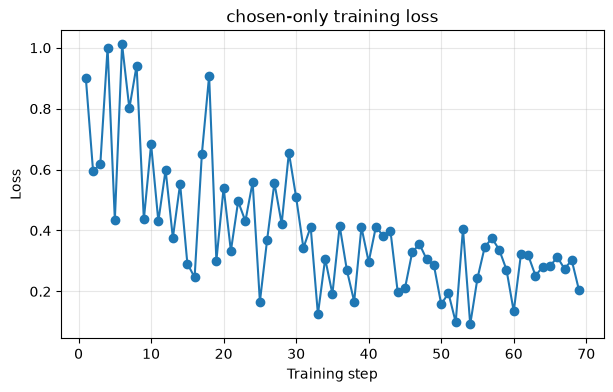

In [10]:
chosen_only_log = train_adapter("chosen-only", pairs)
report_training(chosen_only_log)

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

Loading weights:   1%|          | 3/338 [00:00<00:22, 14.70it/s]

Loading weights:   1%|▏         | 5/338 [00:00<00:44,  7.41it/s]

Loading weights:   4%|▍         | 15/338 [00:00<00:15, 20.40it/s]

Loading weights:   5%|▌         | 18/338 [00:01<00:21, 14.69it/s]

Loading weights:   8%|▊         | 27/338 [00:01<00:14, 21.25it/s]

... (58 outputs left out)

Dropping fully truncated examples from train dataset: 100%|██████████| 92/92 [00:00<00:00, 36110.42 examples/s]

policy is a PeftModel: True
separate reference model: None


Step,Training Loss
1,0.690385
2,0.692204
3,0.697780
4,0.684431
5,0.661674
6,0.657891
7,0.684461
8,0.701537
9,0.632392
10,0.704353


saved a5-dpo
objective: dpo
epochs: 3, learning rate: 0.0001
pairs: 92
trainable params: 4,358,144 of 1,548,072,448
wall clock training time: 644.7 seconds (10.7 minutes)


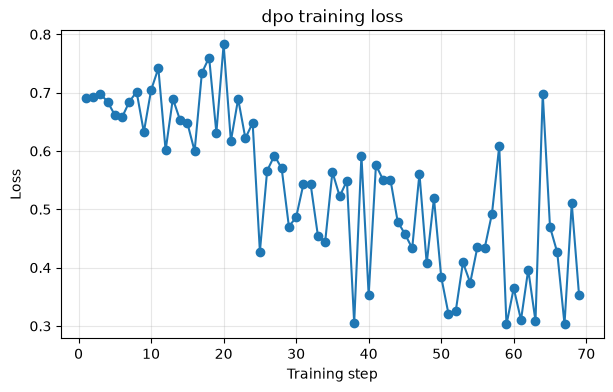

In [11]:
dpo_log = train_adapter("dpo", pairs)
report_training(dpo_log)

## Part C: Evaluate all three

All three adapters are loaded onto one copy of the 4-bit base model, and I switch between them. Every model is scored on the same `test[:50]` with the same extraction rule and harness. The sft model is re-run here, not copied from Assignment 4.

- **Evaluation 1:** greedy decoding, one completion per problem, the three buckets.
- **Evaluation 2:** 10 samples per problem at temperature 0.8, then pass@1 and pass@5 with the unbiased estimator `1 - C(n-c, k) / C(n, k)`, n = 10, averaged over the 50 problems.

Generations are saved in `data/`, and both tables are built from `results.csv`.

In [12]:
ADAPTER_KEYS = {"sft": "sft", "chosen-only": "chosen_only", "dpo": "dpo"}

eval_model = PeftModel.from_pretrained(load_base_model(), ADAPTERS["sft"], adapter_name=ADAPTER_KEYS["sft"])
for name in ["chosen-only", "dpo"]:
    eval_model.load_adapter(ADAPTERS[name], adapter_name=ADAPTER_KEYS[name])
eval_model.eval()


def use_model(name):
    eval_model.set_adapter(ADAPTER_KEYS[name])
    return eval_model


def greedy_eval(name):
    path = os.path.join(DATA_DIR, f"greedy_{name}.json")
    if os.path.isfile(path):
        with open(path, encoding="utf-8") as handle:
            rows = json.load(handle)
        if len(rows) == EVAL_COUNT:
            return rows
    model = use_model(name)
    rows = []
    started = time.perf_counter()
    for problem in eval_problems:
        generation = generate_greedy(model, make_prompt(problem["text"]))
        extracted = extract_function(generation)
        bucket, failure = run_tests(extracted, problem["test_list"])
        rows.append({"task_id": int(problem["task_id"]), "generation": generation,
                     "extracted": extracted, "bucket": bucket, "failure": failure})
    with open(path, "w", encoding="utf-8") as handle:
        json.dump(rows, handle, indent=2)
    print(f"{name}: greedy evaluation took {(time.perf_counter() - started) / 60:.1f} minutes")
    return rows


def sampled_eval(name):
    path = os.path.join(DATA_DIR, f"sampled_{name}.jsonl")
    return sample_and_score(use_model(name), eval_problems, EVAL_SAMPLES, path, seed_offset=1000)


greedy_rows = {name: greedy_eval(name) for name in MODEL_ORDER}
sampled_rows = {name: sampled_eval(name) for name in MODEL_ORDER}

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

Loading weights:   1%|          | 3/338 [00:00<00:18, 18.33it/s]

Loading weights:   1%|▏         | 5/338 [00:00<00:30, 10.81it/s]

Loading weights:   4%|▍         | 15/338 [00:00<00:10, 31.77it/s]

Loading weights:   6%|▌         | 19/338 [00:00<00:11, 26.65it/s]

Loading weights:   8%|▊         | 27/338 [00:00<00:08, 35.03it/s]

... (97 outputs left out)

40/50 new problems sampled (23.3 min)


44/50 new problems sampled (25.7 min)


48/50 new problems sampled (28.1 min)


50/50 new problems sampled (29.5 min)


In [13]:
def pass_at_k(n, c, k):
    if n - c < k:
        return 1.0
    return 1.0 - math.comb(n - c, k) / math.comb(n, k)


def results_table():
    rows = []
    for name in MODEL_ORDER:
        counts = count_buckets(row["bucket"] for row in greedy_rows[name])
        rows.append({"model": name, "evaluation": "greedy", **counts, "total": EVAL_COUNT,
                     "pass_rate": counts["passes"] / EVAL_COUNT, "pass_at_1": None, "pass_at_5": None})
    for name in MODEL_ORDER:
        problems = sampled_rows[name]
        buckets = [s["bucket"] for row in problems for s in row["samples"]]
        counts = count_buckets(buckets)
        correct = [sum(s["bucket"] == "passes" for s in row["samples"]) for row in problems]
        p1 = sum(pass_at_k(EVAL_SAMPLES, c, 1) for c in correct) / len(correct)
        p5 = sum(pass_at_k(EVAL_SAMPLES, c, 5) for c in correct) / len(correct)
        rows.append({"model": name, "evaluation": "sampled", **counts, "total": len(buckets),
                     "pass_rate": counts["passes"] / len(buckets), "pass_at_1": p1, "pass_at_5": p5})
    return pd.DataFrame(rows)


results_table().to_csv(RESULTS_PATH, index=False)
results = pd.read_csv(RESULTS_PATH)
print("saved", RESULTS_PATH)

saved results.csv


### Evaluation 1: greedy (from `results.csv`)

In [14]:
greedy_table = results[results["evaluation"] == "greedy"].set_index("model")
greedy_table = greedy_table[BUCKETS].rename(columns=BUCKET_LABELS)
print(greedy_table.to_string())

             No function  Runs, fails tests  Passes
model                                              
sft                    0                 45       5
chosen-only            1                 46       3
dpo                    2                 45       3


### Evaluation 2: sampled, n = 10 at temperature 0.8 (from `results.csv`)

In [15]:
sampled_table = results[results["evaluation"] == "sampled"].set_index("model")
sampled_table = sampled_table[["pass_at_1", "pass_at_5"]].rename(columns={"pass_at_1": "pass@1", "pass_at_5": "pass@5"})
print(sampled_table.round(3).to_string())

             pass@1  pass@5
model                      
sft           0.022   0.089
chosen-only   0.048   0.115
dpo           0.046   0.121


## Measurements for questions 4 and 5

**Question 4.** For every pair, I add up the log-probability of each completion token given the prompt, once with the sft adapter and once with the dpo adapter. The end-of-text token is included, because both trainers add it to the completion.

In [16]:
def completion_logprob(model, prompt, completion):
    prompt_ids = tokenizer(prompt)["input_ids"]
    completion_ids = tokenizer(completion + tokenizer.eos_token, add_special_tokens=False)["input_ids"]
    device = next(model.parameters()).device
    input_ids = torch.tensor([prompt_ids + completion_ids], device=device)
    with torch.no_grad():
        logits = model(input_ids=input_ids).logits.float()
    log_probs = torch.log_softmax(logits[0, :-1], dim=-1)
    targets = input_ids[0, 1:]
    token_log_probs = log_probs.gather(1, targets.unsqueeze(1)).squeeze(1)
    return token_log_probs[len(prompt_ids) - 1 :].sum().item()


LOGPROB_PATH = os.path.join(DATA_DIR, "logprobs.json")
if os.path.isfile(LOGPROB_PATH):
    with open(LOGPROB_PATH, encoding="utf-8") as handle:
        logprobs = json.load(handle)
else:
    logprobs = {}
    for name in ["sft", "dpo"]:
        model = use_model(name)
        logprobs[name] = [
            {"task_id": p["task_id"],
             "chosen": completion_logprob(model, p["prompt"], p["chosen"]),
             "rejected": completion_logprob(model, p["prompt"], p["rejected"])}
            for p in pairs
        ]
    with open(LOGPROB_PATH, "w", encoding="utf-8") as handle:
        json.dump(logprobs, handle, indent=2)

for name in ["sft", "dpo"]:
    chosen = sum(r["chosen"] for r in logprobs[name]) / len(logprobs[name])
    rejected = sum(r["rejected"] for r in logprobs[name]) / len(logprobs[name])
    print(f"{name:4}  mean log pi(chosen) = {chosen:8.2f}   mean log pi(rejected) = {rejected:8.2f}"
          f"   margin = {chosen - rejected:7.2f}")

sft   mean log pi(chosen) =   -11.56   mean log pi(rejected) =   -18.59   margin =    7.03
dpo   mean log pi(chosen) =   -40.59   mean log pi(rejected) =   -58.94   margin =   18.35


**Question 5.** I take the first 20 mixed problems (in training-set order) and sample 4 fresh completions from the dpo model at temperature 0.8. The "kind of failure" is the error name the harness recorded: `no_function`, `timeout`, or the Python error such as `NameError` or `AssertionError`. A problem counts if at least one of the 4 fresh samples fails with the same kind as that problem's rejected completion.

In [17]:
stale_pairs = pairs[:STALE_PROBLEMS]
stale_ids = {p["task_id"] for p in stale_pairs}
stale_problems = [p for p in train_problems if int(p["task_id"]) in stale_ids]
stale_rows = sample_and_score(
    use_model("dpo"), stale_problems, STALE_SAMPLES, os.path.join(DATA_DIR, "staleness_dpo.jsonl"), seed_offset=2000
)
stale_by_id = {row["task_id"]: row for row in stale_rows}

repeats = 0
for pair in stale_pairs:
    fresh = stale_by_id[pair["task_id"]]["samples"]
    kinds = [s["failure"] for s in fresh]
    same = pair["rejected_failure"] in kinds
    repeats += same
    passed = sum(s["bucket"] == "passes" for s in fresh)
    print(f"task {pair['task_id']:4d}  rejected failure: {pair['rejected_failure']:15}  "
          f"fresh: {kinds}  passes {passed}/4  same kind: {same}")
print()
print(f"Same kind of failure as the rejected completion: {repeats}/{len(stale_pairs)}"
      f" = {repeats / len(stale_pairs):.2f}")

4/20 new problems sampled (1.0 min)


8/20 new problems sampled (2.0 min)


12/20 new problems sampled (3.1 min)


16/20 new problems sampled (4.1 min)


20/20 new problems sampled (5.2 min)


task  602  rejected failure: NameError        fresh: ['NameError', 'NameError', 'NameError', 'NameError']  passes 0/4  same kind: True
task  604  rejected failure: NameError        fresh: [None, 'no_function', 'AssertionError', 'NameError']  passes 1/4  same kind: True
task  605  rejected failure: NameError        fresh: ['NameError', 'NameError', 'NameError', 'NameError']  passes 0/4  same kind: True
task  616  rejected failure: NameError        fresh: [None, None, None, None]  passes 4/4  same kind: False
task  625  rejected failure: NameError        fresh: ['NameError', 'NameError', 'NameError', 'NameError']  passes 0/4  same kind: True
task  628  rejected failure: NameError        fresh: [None, None, 'AssertionError', 'NameError']  passes 2/4  same kind: True
task  631  rejected failure: NameError        fresh: ['no_function', 'NameError', 'NameError', 'NameError']  passes 0/4  same kind: True
task  632  rejected failure: NameError        fresh: ['NameError', 'NameError', 'NameErro

## Questions

### 1. Coverage

Out of 374 training problems, **0** were all pass, **282** were all fail, and **92** were mixed. That gave **92 pairs**. Across all 2,992 completions, 219 passed, 2,742 ran but failed, and 31 had no function.

**All fail (282 problems).** The model never got these right in 8 tries, so there was no good answer to choose. These are exactly the problems the model most needs help with, and they gave no training signal at all. Most of them failed with `NameError`: the model wrote a function under a different name than the one the tests call.

**All pass (0 problems).** In my run this group is empty. If a problem did land here, it would teach nothing for the opposite reason: there would be no bad answer to push away from, because the model has already solved it.

So the all-fail group is useless because there is no "good" answer, and the all-pass group is useless because there is no "bad" answer. Only the middle 92 problems (25% of the data) were used.

### 2. Attribution

Evaluation 1 (greedy, out of 50):

| Model | No function | Runs, fails tests | Passes |
|---|---|---|---|
| sft | 0 | 45 | 5 |
| chosen-only | 1 | 46 | 3 |
| dpo | 2 | 45 | 3 |

**Did preference optimization beat supervised training on the same answers?** No. dpo and chosen-only both passed 3 of 50. They did not pass the same problems (chosen-only passed tasks 12, 37, 54; dpo passed 17, 24, 37), but the count is a tie. Both are below the sft model (5 of 50), which was trained on 374 reference answers instead of 92 sampled ones.

**What can be attributed to the preference signal?** Nothing good on greedy pass rate. chosen-only and dpo were trained on the same pairs with the same settings, so the difference between them comes from the objective. The clearest difference is the *style* of the answers, not their correctness: chosen-only's greedy answers average 43 tokens, while dpo's average 240 tokens, and 36 of 50 dpo answers ran all the way to the 256-token limit. dpo usually starts with an explanation ("To find the largest prime factor... we can use the following steps") and sometimes writes in another language (task 15 answered in JavaScript), which is where its 2 "no function" results came from. So the preference signal changed how the model writes, but did not make it pass more tests.

**Compared with my prediction.** I predicted dpo would be within one or two problems of chosen-only. That was right: they tied. I did not predict that both would score below sft.

### 3. The two evaluations

| | sft | dpo |
|---|---|---|
| pass@1 | 0.022 | 0.046 |
| pass@5 | 0.089 | 0.121 |

Both moved **up** from sft to dpo, so they moved in the same direction. I did not see the pattern where pass@1 goes up and pass@5 goes down. dpo did not get worse at what it can reach with several tries.

For someone deploying the model, this means that if they let the model try several times and keep an answer that passes the tests, dpo is a little better than sft. But if they only take the single greedy answer, dpo is worse (3 vs 5 of 50), and its answers are long and full of explanation. Also, chosen-only got almost the same sampled numbers (pass@1 0.048, pass@5 0.115), so this gain over sft comes from training on the filtered passing answers, not from the preference signal.

### 4. The log-probability check

Average log-probability of the full completion (plus end-of-text) over all 92 pairs:

| | log pi(chosen) | log pi(rejected) | margin |
|---|---|---|---|
| sft | -11.56 | -18.59 | 7.03 |
| dpo | -40.59 | -58.94 | 18.35 |

**Did the margin grow?** Yes, from 7.03 to 18.35.

**Did log pi(chosen) go up or down?** Down, by a lot: from -11.56 to -40.59. The rejected answer went down even more, which is why the margin still grew.

So the dpo model did not learn to like the chosen answer more than sft does. It learned to push the rejected answer down *faster* than the chosen answer. In other words, it learned "these failing answers are unlikely" much more than "these passing answers are likely."

**Where did the probability mass go?** To answers that are not in the pairs at all: long, explaining, tutorial-style text. That shows up in the evaluations: dpo's greedy answers average 240 tokens (sft: 47), and 218 of its 500 sampled answers hit the 256-token limit (sft: 2). The short "write the function and stop" answers that sft puts its probability on are now much less likely under dpo. Part of the reason is that dpo started from the base model and its reference is the base model with the adapter off, so nothing in its objective ever pulled it toward the short answer format that sft learned.

### 5. Staleness

On the first 20 mixed problems, I sampled 4 fresh completions from the dpo model. On **16 of 20 problems (0.80)**, at least one fresh completion still failed in the same way as that problem's rejected completion. Almost all of those were `NameError`, the wrong-function-name failure. On 3 problems all 4 fresh samples passed, and on 1 problem (task 635) the old `IndexError` was replaced by a new `NameError`.

The rejected answers were collected from the sft model before training began, and nobody checked them again once the dpo model started changing. So the model was trained to avoid mistakes from an old version of itself, and most of the time it still made the same kind of mistake, while it also picked up new habits (long explanations) that no pair ever pushed back against.

### 6. Two objectives side by side

**DPO (Part B):**

L_DPO = - log sigmoid( beta * [ s(y_chosen) - s(y_rejected) ] ), where s(y) = log pi_theta(y | x) - log pi_ref(y | x)

**GRPO:** for each prompt x, sample a group of G answers o_1 ... o_G from the old policy pi_old, score each with a reward r_i (1 if it passes the tests, 0 if not), and compute the advantage A_i = (r_i - mean(r)) / std(r). Then maximize

J_GRPO = average over i and tokens t of min( rho_i,t * A_i , clip(rho_i,t, 1 - eps, 1 + eps) * A_i ) - beta * KL(pi_theta || pi_ref), where rho_i,t = pi_theta(o_i,t | x, o_i,<t) / pi_old(o_i,t | x, o_i,<t)

**Terms that match:**
- pi_theta (the model being trained) appears in both.
- pi_ref (the frozen reference) appears in both.
- beta appears in both, and in both it limits how far pi_theta can move from pi_ref. In DPO this happens inside the log ratio s(y); in GRPO it is a separate KL penalty.
- The pass/fail label matches. In DPO it decides which answer is chosen and which is rejected; in GRPO it is the reward r_i.
- "chosen minus rejected" in DPO matches the advantage A_i in GRPO. Both say "push up the better answer compared to the worse one."

**Terms in GRPO with no counterpart in DPO:** the old policy pi_old and the ratio rho, the clipping and its range eps, the group of G answers, the group mean and standard deviation used to compute A_i, and the separate KL term.

**Terms in DPO with no counterpart in GRPO:** the log-sigmoid, and the fixed pair (y_chosen, y_rejected) that is given as input instead of being sampled.

**The property Option 3 needs that DPO does not have:** GRPO samples new answers from the current model *inside the training loop* (it is on-policy). DPO only uses pairs that were collected once, before training started, and never samples during training.